# Tarea 4: Pronóstico de Generación Hidroeléctrica con Redes Neuronales Recurrentes (LSTM)

**Autores:** Jossely Mendoza, Jefferson Olalla, Juan Asimbaya & Juan Coronel

**Problema:** Predicción multivariable a 24 horas vista (*Day-Ahead Forecasting*) de la central hidroeléctrica Paute-Molino  
**Conjunto de datos:** CELEC EP (Complejo Hidroeléctrico Paute y Minas San Francisco, Ecuador - Dataset EDADES)  
**Técnica:** Redes Recurrentes LSTM (Single LSTM vs Stacked LSTM) con ventanas deslizantes (*Sliding Windows*)


## 1. Configuración de Entorno e Importación de Librerías


In [1]:
# Dependencias principales
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocesamiento y métricas
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Deep Learning con TensorFlow / Keras (Arquitecturas LSTM)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Configuración de reproducibilidad y estilos
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 10


## 2. Carga y Normalización del Conjunto de Datos
Se cargan los registros horarios de generación eléctrica y unidades operativas de las centrales hidroeléctricas administradas por CELEC EP:
* **Paute-Molino** (Variable objetivo: central base del sistema nacional)
* **Mazar** (Embalse regulador aguas arriba en la cuenca del Paute)
* **Sopladora** (Central aguas abajo de Molino)
* **Minas San Francisco** (Cuenca Jubones)


In [2]:
DATA_PATH = './data/datos_celec_v1.csv'

# Carga de datos
df = pd.read_csv(DATA_PATH)

# Saneamiento de nombres de columnas (eliminar caracteres no imprimibles y espacios)
df.columns = [c.replace('\xad', '').strip() for c in df.columns]

# Conversión y ordenamiento cronológico
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df = df.sort_values('Timestamp').reset_index(drop=True)

print(f"Dimensiones del dataset: {df.shape[0]} registros horarios, {df.shape[1]} columnas.")
print(f"Rango temporal: desde {df['Timestamp'].min()} hasta {df['Timestamp'].max()}")
print(f"Total valores nulos: {df.isnull().sum().sum()}")
df.head()


Dimensiones del dataset: 11136 registros horarios, 9 columnas.
Rango temporal: desde 2024-01-01 01:00:00 hasta 2025-04-09 00:00:00
Total valores nulos: 0


,Timestamp,Energía_Molino,Energía_Mazar,Energía_Sopladora,Energía_Minas_San_Francisco,Unidades_Molino,Unidades_Mazar,Unidades_Sopladora,Unidades_Minas_San_Francisco
0,2024-01-01 01:00:00,271.743420,0.0,162.304304,272.00,4,0,1,3
1,2024-01-01 02:00:00,271.321353,0.0,157.102239,272.25,4,0,1,3
2,2024-01-01 03:00:00,253.509839,0.0,153.176297,271.38,4,0,1,3
3,2024-01-01 04:00:00,184.495683,0.0,109.630119,272.25,3,0,1,3
4,2024-01-01 05:00:00,186.025423,0.0,106.103861,271.50,3,0,1,3


## 3. Análisis Exploratorio de Datos (EDA)


In [3]:
# Resumen estadístico de las variables continuas y operativas
resumen = df.describe().T[['mean', 'std', 'min', '50%', 'max']]
resumen.round(2)


,mean,std,min,50%,max
Timestamp,2024-08-20 00:30:00,NaN,2024-01-01 01:00:00,2024-08-20 00:30:00,2025-04-09 00:00:00
Energía_Molino,447.885673,294.549008,0.0,451.091865,1114.359284
Energía_Mazar,54.954352,63.060847,0.0,21.01283,170.963946
Energía_Sopladora,233.358171,141.398903,0.0,261.208371,456.340451
Energía_Minas_San_Francisco,107.636503,103.463516,0.0,69.185,275.13
Unidades_Molino,6.299749,3.334643,0.0,7.0,10.0
Unidades_Mazar,0.818247,0.862538,0.0,1.0,2.0
Unidades_Sopladora,1.765535,0.987247,0.0,2.0,3.0
Unidades_Minas_San_Francisco,1.971624,1.110873,0.0,2.0,3.0


### Diagnóstico estadístico inicial
* **Paute-Molino:** media de 447.89 MWh y desviación estándar de 294.55 MWh (coeficiente de variación de 65.8%). El rango va de 0 a 1,114.36 MWh. Esta dispersión se debe al despacho horario y a los meses de baja generación.
* **Unidades en servicio:** Molino opera en promedio con 6.30 unidades (máximo 10), Sopladora con 1.77 (máximo 3) y Mazar con 0.82 (máximo 2).
* **Continuidad:** no hay nulos, duplicados ni saltos: entre el primer y el último registro caben exactamente 11,136 horas y el dataset tiene 11,136 filas.

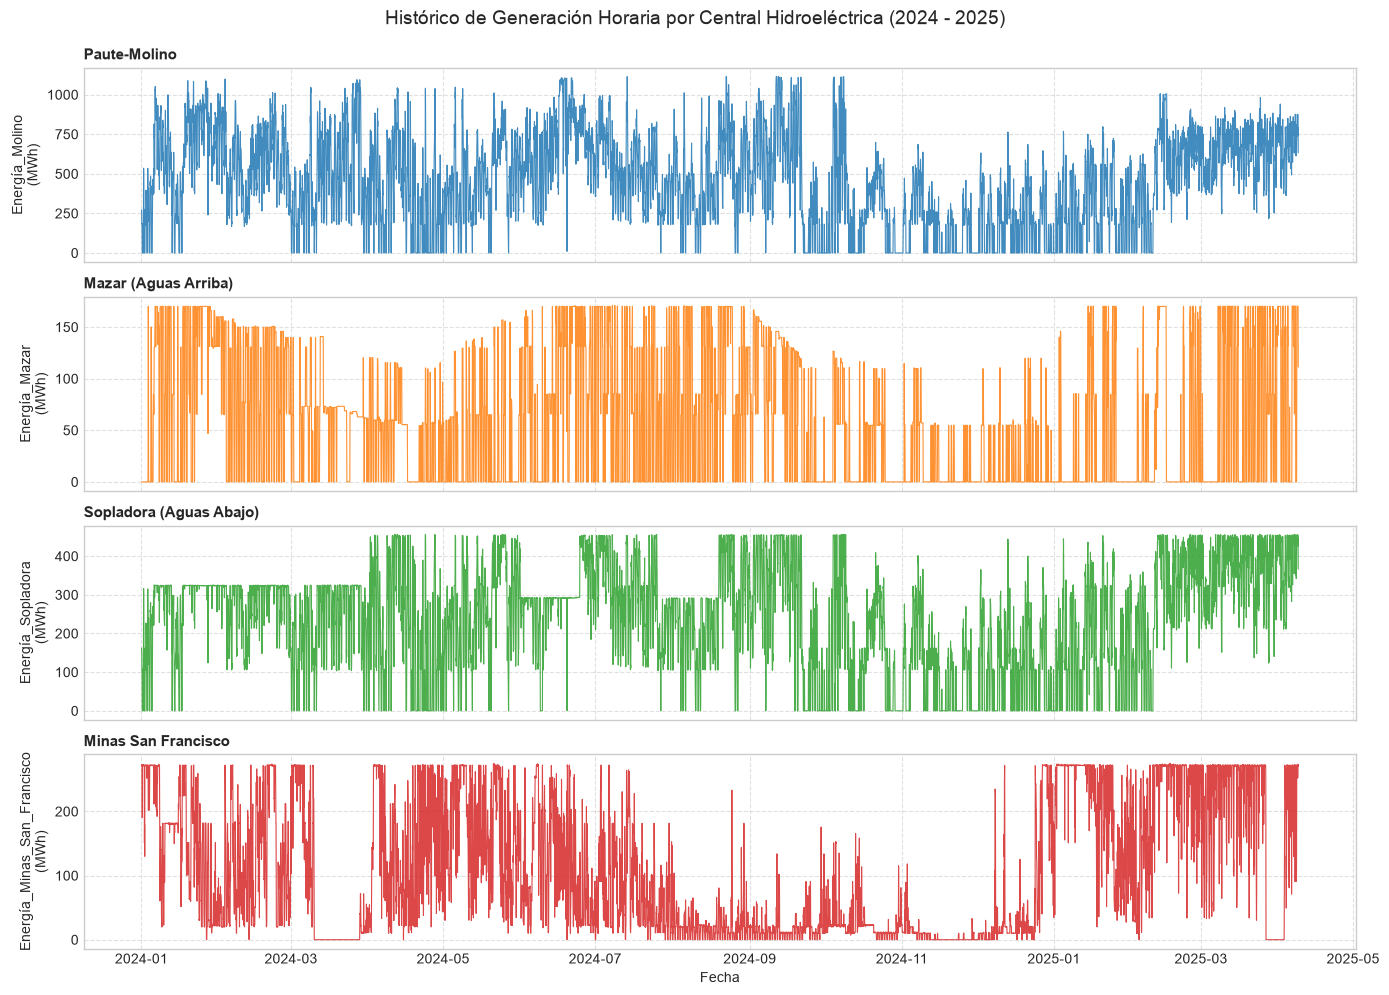

In [4]:
# Visualización de la serie temporal continua de generación
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

centrales = [
    ('Energía_Molino', 'Paute-Molino', '#1f77b4'),
    ('Energía_Mazar', 'Mazar (Aguas Arriba)', '#ff7f0e'),
    ('Energía_Sopladora', 'Sopladora (Aguas Abajo)', '#2ca02c'),
    ('Energía_Minas_San_Francisco', 'Minas San Francisco', '#d62728')
]

for ax, (col, title, color) in zip(axes, centrales):
    ax.plot(df['Timestamp'], df[col], color=color, linewidth=0.8, alpha=0.85)
    ax.set_ylabel(f'{col}\n(MWh)')
    ax.set_title(title, loc='left', fontweight='bold', fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.6)

axes[-1].set_xlabel('Fecha')
plt.suptitle('Histórico de Generación Horaria por Central Hidroeléctrica (2024 - 2025)', fontsize=14, y=0.99)
plt.tight_layout()
plt.show()


### Dinámica temporal
* **Periodo de baja generación:** los promedios mensuales de Molino caen de 502 MWh en septiembre de 2024 a 269 en octubre, 154 en noviembre y 180 en diciembre, y se recuperan en enero (272) y febrero (503). En la gráfica se ven además varios tramos con generación en 0 (1,572 horas con menos de 1 MWh en todo el dataset). Los datos no dicen la causa; que se deba a sequía o racionamientos es una explicación externa que habría que respaldar con otra fuente.
* **Mazar:** casi la mitad de las horas está en 0 (5,350 de 11,136) y, cuando opera, suele saturarse cerca de 170 MWh. Esa saturación se mantiene hasta septiembre de 2024, de modo que Mazar no acompaña la caída de Molino desde el inicio.
* **Molino y Sopladora:** se mueven juntas en general, pero Sopladora tiene tramos planos (~325 MWh en enero–marzo y ~290 en junio de 2024) en los que Molino sigue variando, así que la coincidencia no es total.

Pico diario      : Hora 20:00 con 586.55 MWh
Valle diario     : Hora 5:00 con 269.63 MWh
Amplitud diaria  : 316.92 MWh (+117.5%)
Promedio laboral : 468.53 MWh (Lun - Vie)
Promedio domingo : 345.55 MWh (reducción del 26.2%)


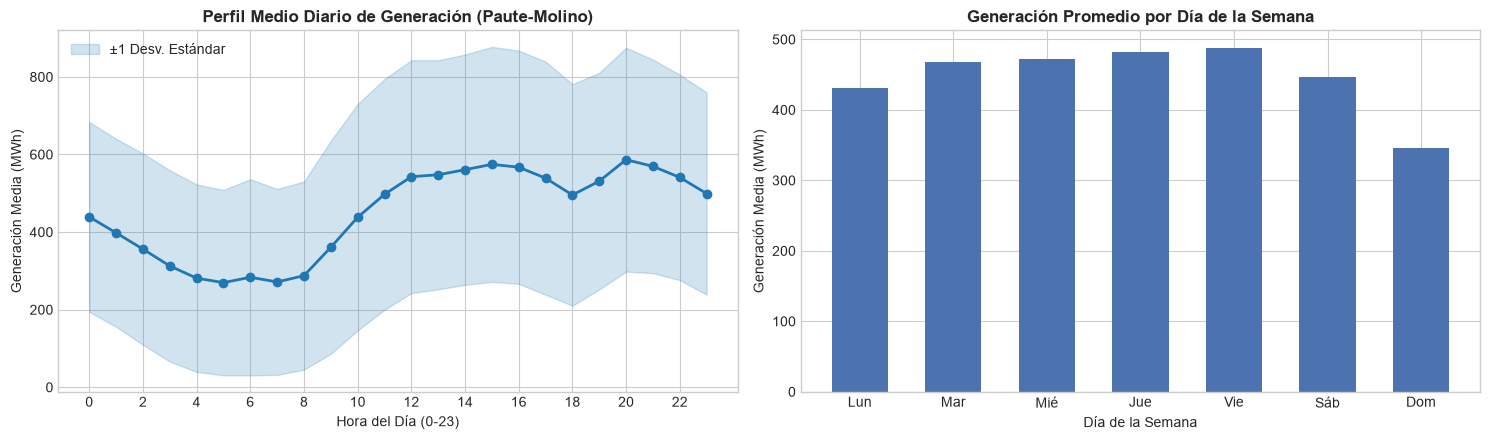

In [5]:
# Análisis cuantitativo de estacionalidad horaria y semanal en Paute-Molino
df['Hora'] = df['Timestamp'].dt.hour
df['DiaSemana'] = df['Timestamp'].dt.day_name()
dias_orden = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

perfil_horario = df.groupby('Hora')['Energía_Molino'].agg(['mean', 'std']).reset_index()
perfil_semanal = df.groupby('DiaSemana')['Energía_Molino'].mean().reindex(dias_orden)

# Cálculo de métricas puntuales para verificación
pico_hora = perfil_horario.loc[perfil_horario['mean'].idxmax(), 'Hora']
pico_val = perfil_horario['mean'].max()
valle_hora = perfil_horario.loc[perfil_horario['mean'].idxmin(), 'Hora']
valle_val = perfil_horario['mean'].min()
prom_laboral = perfil_semanal.loc[['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']].mean()
prom_domingo = perfil_semanal.loc['Sunday']

print(f"Pico diario      : Hora {pico_hora}:00 con {pico_val:.2f} MWh")
print(f"Valle diario     : Hora {valle_hora}:00 con {valle_val:.2f} MWh")
print(f"Amplitud diaria  : {pico_val - valle_val:.2f} MWh (+{((pico_val/valle_val)-1)*100:.1f}%)")
print(f"Promedio laboral : {prom_laboral:.2f} MWh (Lun - Vie)")
print(f"Promedio domingo : {prom_domingo:.2f} MWh (reducción del {((1 - prom_domingo/prom_laboral)*100):.1f}%)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))

ax1.plot(perfil_horario['Hora'], perfil_horario['mean'], color='#1f77b4', marker='o', linewidth=2)
ax1.fill_between(perfil_horario['Hora'], 
                 perfil_horario['mean'] - perfil_horario['std'], 
                 perfil_horario['mean'] + perfil_horario['std'], 
                 color='#1f77b4', alpha=0.2, label='±1 Desv. Estándar')
ax1.set_title('Perfil Medio Diario de Generación (Paute-Molino)', fontweight='bold')
ax1.set_xlabel('Hora del Día (0-23)')
ax1.set_ylabel('Generación Media (MWh)')
ax1.set_xticks(range(0, 24, 2))
ax1.legend()

ax2.bar(range(7), perfil_semanal.values, color='#4c72b0', width=0.6)
ax2.set_title('Generación Promedio por Día de la Semana', fontweight='bold')
ax2.set_xlabel('Día de la Semana')
ax2.set_ylabel('Generación Media (MWh)')
ax2.set_xticks(range(7))
ax2.set_xticklabels(['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom'])

plt.tight_layout()
plt.show()


### Estacionalidades circadiana y semanal
* **Ciclo diario:** el máximo está a las 20:00 con 586.55 MWh y el mínimo a las 05:00 con 269.63 MWh. La diferencia es de 316.92 MWh (el pico es 117.5% mayor que el valle). Las 20:00 y 21:00 son las únicas horas del bloque nocturno que pasan de 565 MWh; a las 19:00 el promedio es 531.
* **Ciclo semanal:** de lunes a viernes el promedio por día va de 431.73 a 488.26 MWh, con 468.53 MWh en conjunto. El domingo baja a 345.55 MWh, un 26.2% menos que los días laborales. Una explicación posible es la menor demanda industrial y comercial, pero eso no se puede comprobar con este dataset.

Correlación de Pearson frente a Energía_Molino:
                              Energía_Molino
Energía_Molino                         1.000
Energía_Mazar                          0.622
Energía_Sopladora                      0.928
Energía_Minas_San_Francisco            0.187
Unidades_Molino                        0.906
Unidades_Mazar                         0.593
Unidades_Sopladora                     0.842
Unidades_Minas_San_Francisco           0.178


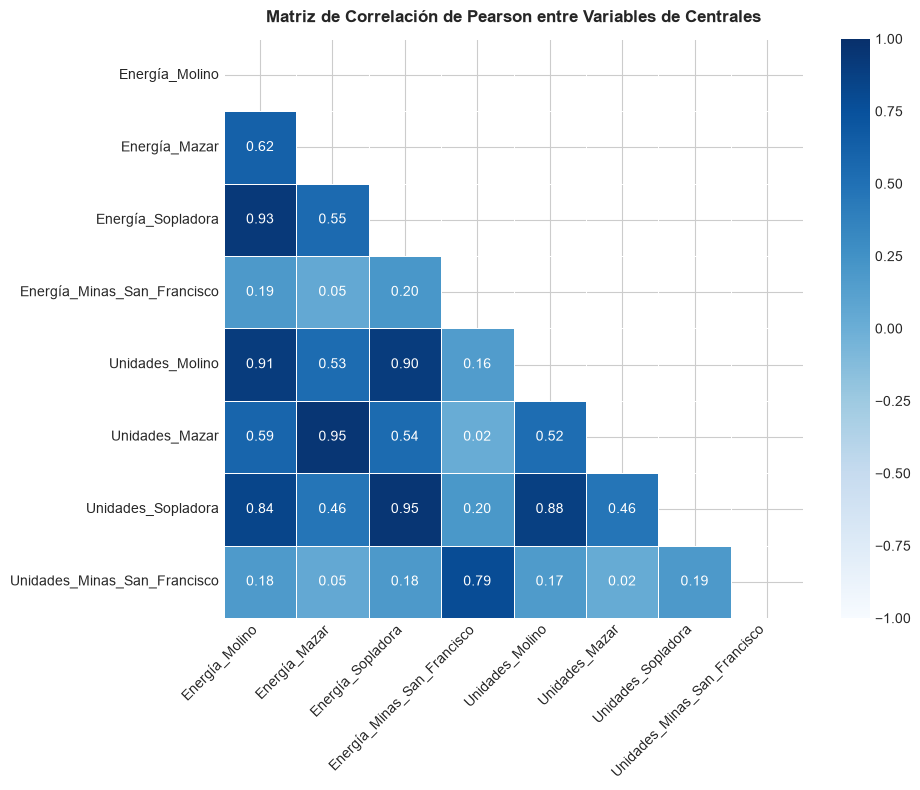

In [6]:
# Matriz de correlación de Pearson
cols_analisis = [c for c in df.columns if c.startswith('Energía_') or c.startswith('Unidades_')]
corr = df[cols_analisis].corr()

# Impresión de coeficientes directos frente a la variable objetivo
print("Correlación de Pearson frente a Energía_Molino:")
print(corr[['Energía_Molino']].round(3))

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='Blues', vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('Matriz de Correlación de Pearson entre Variables de Centrales', fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### Relación entre centrales y unidades
* **Molino vs Sopladora (r = 0.93):** correlación muy alta, coherente con que Sopladora está aguas abajo de Molino.
* **Molino vs Unidades_Molino (r = 0.91):** esperable, porque la potencia depende de cuántas turbinas están conectadas.
* **Molino vs Mazar (r = 0.62):** correlación positiva moderada.
* **Molino vs Minas San Francisco (r = 0.19):** correlación baja. Minas San Francisco pertenece a otra cuenca (Jubones), lo que es consistente con este valor, aunque la correlación sola no lo demuestra.

Correlación Cruzada Mazar(t) vs Molino(t + lag):
Lag 0  : 0.622 (máximo)
Lag 1h : 0.614
Lag 2h : 0.592
Lag 3h : 0.562

Autocorrelación de Energía_Molino en lags clave:
Lag   1 horas: r = 0.967
Lag  24 horas: r = 0.742
Lag  48 horas: r = 0.618
Lag  72 horas: r = 0.569
Lag 168 horas: r = 0.521


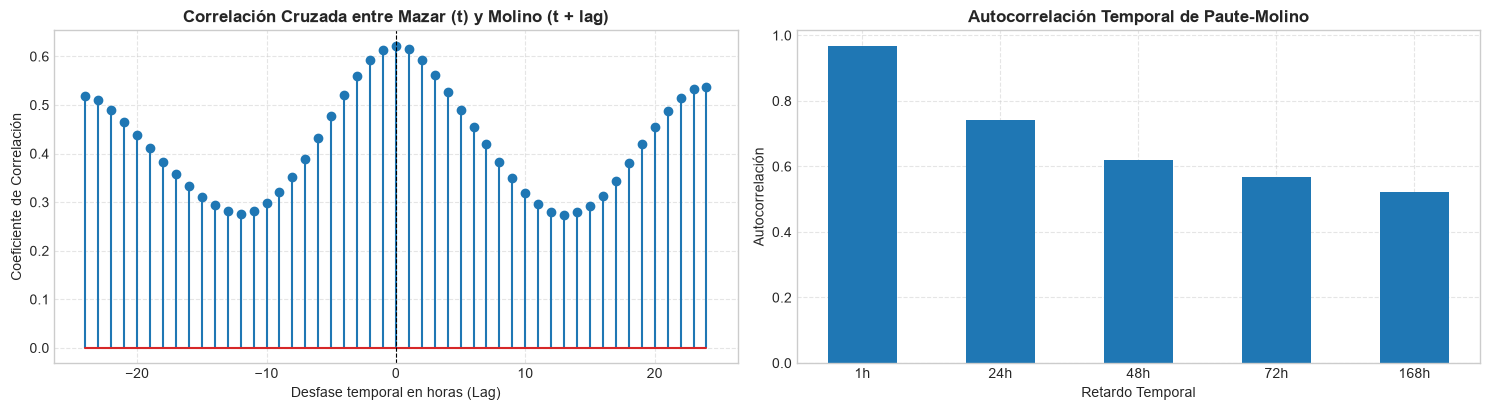

In [7]:
# Análisis de Correlación Cruzada (Mazar vs Molino) y Autocorrelación Temporal
lags = range(-24, 25)
cross_corr = [df['Energía_Mazar'].corr(df['Energía_Molino'].shift(lag)) for lag in lags]
s_cross = pd.Series(cross_corr, index=lags)

# Autocorrelaciones para justificar el lookback
autocorr_lags = [1, 24, 48, 72, 168]
autocorr_vals = [df['Energía_Molino'].autocorr(lag=l) for l in autocorr_lags]

print("Correlación Cruzada Mazar(t) vs Molino(t + lag):")
print(f"Lag 0  : {s_cross.loc[0]:.3f} (máximo)")
print(f"Lag 1h : {s_cross.loc[1]:.3f}")
print(f"Lag 2h : {s_cross.loc[2]:.3f}")
print(f"Lag 3h : {s_cross.loc[3]:.3f}\n")

print("Autocorrelación de Energía_Molino en lags clave:")
for l, val in zip(autocorr_lags, autocorr_vals):
    print(f"Lag {l:3d} horas: r = {val:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.2))

# Subplot 1: Cross-correlation
ax1.stem(lags, cross_corr)
ax1.axvline(0, color='black', linestyle='--', linewidth=0.8)
ax1.set_title('Correlación Cruzada entre Mazar (t) y Molino (t + lag)', fontweight='bold')
ax1.set_xlabel('Desfase temporal en horas (Lag)')
ax1.set_ylabel('Coeficiente de Correlación')
ax1.grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Autocorrelation key points
ax2.bar([str(l) + 'h' for l in autocorr_lags], autocorr_vals, color='#1f77b4', width=0.5)
ax2.set_title('Autocorrelación Temporal de Paute-Molino', fontweight='bold')
ax2.set_xlabel('Retardo Temporal')
ax2.set_ylabel('Autocorrelación')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### Dependencia temporal y elección de la ventana (*lookback*)
* **Mazar y Molino:** en el código se usó `Molino.shift(lag)`, que corresponde a Molino(t − lag). Por eso el signo del eje es el contrario al que sugiere el título del gráfico. La correlación es máxima con lag 0 (0.622) y baja despacio hacia ambos lados (lag 1: 0.614; lag 3: 0.562; lag −3: 0.559). Como la curva es casi simétrica, no se ve un retardo claro de Mazar hacia Molino, que era lo que planteaba `task.md`. Lo que se observa es que ambas centrales se mueven juntas dentro de la misma hora.
* **Autocorrelación de Molino:** 0.967 a 1 h, 0.742 a 24 h, 0.618 a 48 h, 0.569 a 72 h y 0.521 a 168 h. Se mantiene por encima de 0.5 incluso a una semana.
* **Elección de 72 horas:** es el valor que pedía la consigna. Con las autocorrelaciones se justifica que cubra tres ciclos diarios, pero no se probaron otras ventanas, así que no sabemos si 72 h es mejor que 24 o 48 h.

## 4. Ingeniería de Características (Feature Engineering)
Para evitar que las redes neuronales perciban discontinuidades numéricas en los cambios de ciclo (por ejemplo, el paso de la hora 23 a la 0), se transforman la hora del día y el día de la semana en coordenadas trigonométricas continuas:
$$\text{hour}_{\sin} = \sin\left(\frac{2\pi \cdot \text{hora}}{24}\right), \quad \text{hour}_{\cos} = \cos\left(\frac{2\pi \cdot \text{hora}}{24}\right)$$
$$\text{dow}_{\sin} = \sin\left(\frac{2\pi \cdot \text{dow}}{7}\right), \quad \text{dow}_{\cos} = \cos\left(\frac{2\pi \cdot \text{dow}}{7}\right)$$


In [8]:
# Codificación cíclica de variables de calendario
df['hour_sin'] = np.sin(2 * np.pi * df['Hora'] / 24.0)
df['hour_cos'] = np.cos(2 * np.pi * df['Hora'] / 24.0)

dow = df['Timestamp'].dt.dayofweek
df['dow_sin'] = np.sin(2 * np.pi * dow / 7.0)
df['dow_cos'] = np.cos(2 * np.pi * dow / 7.0)

# Definición de variables predictoras (features) y variable objetivo (target)
TARGET = 'Energía_Molino'
FEATURE_COLS = [
    'Energía_Molino', 'Energía_Mazar', 'Energía_Sopladora', 'Energía_Minas_San_Francisco',
    'Unidades_Molino', 'Unidades_Mazar', 'Unidades_Sopladora', 'Unidades_Minas_San_Francisco',
    'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos'
]

print(f"Variable objetivo: {TARGET}")
print(f"Total características de entrada: {len(FEATURE_COLS)}")
print(FEATURE_COLS)


Variable objetivo: Energía_Molino
Total características de entrada: 12
['Energía_Molino', 'Energía_Mazar', 'Energía_Sopladora', 'Energía_Minas_San_Francisco', 'Unidades_Molino', 'Unidades_Mazar', 'Unidades_Sopladora', 'Unidades_Minas_San_Francisco', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos']


## 5. Partición Temporal Cronológica (Train, Validation, Test)
En series temporales se mantiene estrictamente el orden cronológico sin barajado (*shuffle=False*) para replicar las condiciones reales de predicción:
* **Entrenamiento (Train):** 70% (~7,795 horas / ~10.5 meses)
* **Validación (Val):** 15% (~1,670 horas / ~2.3 meses)
* **Prueba (Test):** 15% (~1,671 horas / ~2.3 meses)


Train : 2024-01-01 01:00:00 a 2024-11-20 19:00:00 (7795 registros, 70.0%)
Val   : 2024-11-20 20:00:00 a 2025-01-29 09:00:00 (1670 registros, 15.0%)
Test  : 2025-01-29 10:00:00 a 2025-04-09 00:00:00 (1671 registros, 15.0%)


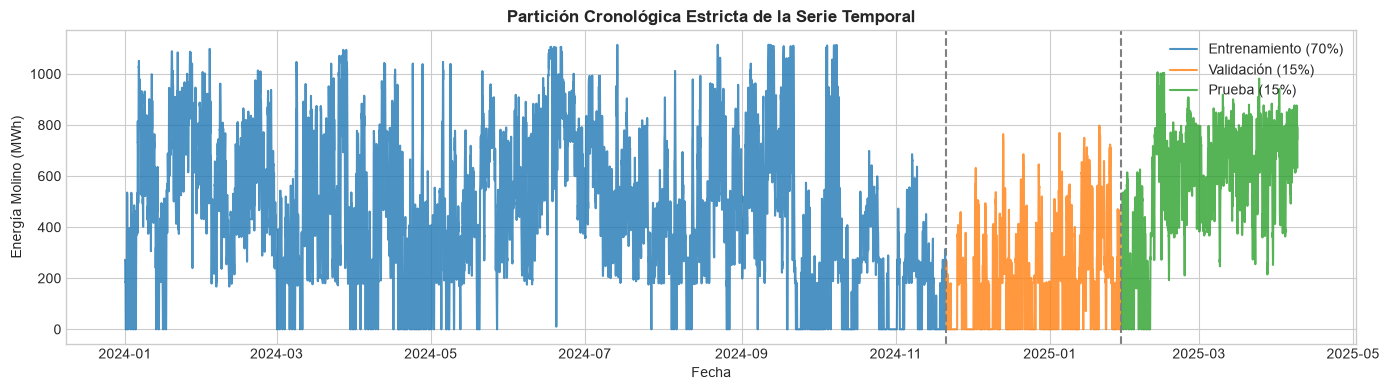

In [9]:
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

print(f"Train : {train_df['Timestamp'].min()} a {train_df['Timestamp'].max()} ({len(train_df)} registros, {len(train_df)/n*100:.1f}%)")
print(f"Val   : {val_df['Timestamp'].min()} a {val_df['Timestamp'].max()} ({len(val_df)} registros, {len(val_df)/n*100:.1f}%)")
print(f"Test  : {test_df['Timestamp'].min()} a {test_df['Timestamp'].max()} ({len(test_df)} registros, {len(test_df)/n*100:.1f}%)")

# Gráfica de partición temporal
plt.figure(figsize=(14, 4))
plt.plot(train_df['Timestamp'], train_df[TARGET], label='Entrenamiento (70%)', color='#1f77b4', alpha=0.8)
plt.plot(val_df['Timestamp'], val_df[TARGET], label='Validación (15%)', color='#ff7f0e', alpha=0.8)
plt.plot(test_df['Timestamp'], test_df[TARGET], label='Prueba (15%)', color='#2ca02c', alpha=0.8)
plt.axvline(train_df['Timestamp'].iloc[-1], color='gray', linestyle='--')
plt.axvline(val_df['Timestamp'].iloc[-1], color='gray', linestyle='--')
plt.title('Partición Cronológica Estricta de la Serie Temporal', fontweight='bold')
plt.ylabel('Energía Molino (MWh)')
plt.xlabel('Fecha')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


## 6. Escalamiento de Datos y Ventanas Deslizantes (*Sliding Windows*)
1. **Normalización:** Se aplica `MinMaxScaler([0, 1])` ajustado **exclusivamente** sobre el conjunto de entrenamiento (`train_df`).
2. **Escalador Objetivo:** Se define un escalador separado para la variable objetivo `scaler_y` para permitir la inversión exacta de las predicciones a $\text{MWh}$.
3. **Formulación de Ventanas:**
   * **Lookback ($T_{\text{in}}$):** 72 horas (3 días previos de contexto multivariable).
   * **Horizon ($T_{\text{out}}$):** 24 horas (pronóstico *Day-Ahead* de las 24 horas consecutivas del día siguiente).
   * Tensores resultantes: $X \in \mathbb{R}^{N \times 72 \times 12}$ e $y \in \mathbb{R}^{N \times 24}$.


In [10]:
# Ajuste de escaladores únicamente sobre Train
scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()

scaler_x.fit(train_df[FEATURE_COLS])
scaler_y.fit(train_df[[TARGET]])

X_train_scaled = scaler_x.transform(train_df[FEATURE_COLS])
y_train_scaled = scaler_y.transform(train_df[[TARGET]])

X_val_scaled = scaler_x.transform(val_df[FEATURE_COLS])
y_val_scaled = scaler_y.transform(val_df[[TARGET]])

X_test_scaled = scaler_x.transform(test_df[FEATURE_COLS])
y_test_scaled = scaler_y.transform(test_df[[TARGET]])

def create_multistep_sequences(features, target, lookback=72, horizon=24):
    X, y = [], []
    for i in range(len(features) - lookback - horizon + 1):
        X.append(features[i:(i + lookback)])
        y.append(target[(i + lookback):(i + lookback + horizon), 0])
    return np.array(X), np.array(y)

LOOKBACK = 72
HORIZON = 24

X_train_seq, y_train_seq = create_multistep_sequences(X_train_scaled, y_train_scaled, LOOKBACK, HORIZON)
X_val_seq, y_val_seq = create_multistep_sequences(X_val_scaled, y_val_scaled, LOOKBACK, HORIZON)
X_test_seq, y_test_seq = create_multistep_sequences(X_test_scaled, y_test_scaled, LOOKBACK, HORIZON)

print(f"Dimensiones de secuencias de entrada (X):")
print(f"Train: {X_train_seq.shape} -> (Muestras, Pasos_Previos, Variables)")
print(f"Val  : {X_val_seq.shape}")
print(f"Test : {X_test_seq.shape}")
print(f"\nDimensiones de salida (y):")
print(f"Train: {y_train_seq.shape} -> (Muestras, Horizonte_24h)")


Dimensiones de secuencias de entrada (X):
Train: (7700, 72, 12) -> (Muestras, Pasos_Previos, Variables)
Val  : (1575, 72, 12)
Test : (1576, 72, 12)

Dimensiones de salida (y):
Train: (7700, 24) -> (Muestras, Horizonte_24h)


### Verificación de ausencia de data leakage
Se hacen tres comprobaciones en el código:
1. **Frontera temporal:** el último timestamp de entrenamiento es anterior al primero de validación, y el último de validación al primero de prueba (`assert`).
2. **Escalador:** los mínimos y máximos del `MinMaxScaler` coinciden con los de `train_df` (`assert`).
3. **Ventanas:** la primera ventana de entrenamiento usa las filas 0 a 71 como entrada y las filas 72 a 95 como objetivo, por lo que la entrada no contiene valores del periodo que se predice (`assert`).

In [11]:
# Verificaciones formales de no-leakage
assert train_df["Timestamp"].max() < val_df["Timestamp"].min(), "Error: Solapamiento temporal Train-Val"
assert val_df["Timestamp"].max() < test_df["Timestamp"].min(), "Error: Solapamiento temporal Val-Test"

# Comprobación de parámetros de escalamiento
check_min = np.allclose(scaler_x.data_min_, train_df[FEATURE_COLS].min().values)
check_max = np.allclose(scaler_x.data_max_, train_df[FEATURE_COLS].max().values)
assert check_min and check_max, "Error: El escalador fue ajustado con datos fuera de Train"

# Validación 3: la primera ventana usa filas 0-71 como entrada y 72-95 como objetivo
assert np.allclose(X_train_seq[0], X_train_scaled[0:LOOKBACK]), "Error: entrada desalineada"
assert np.allclose(y_train_seq[0], y_train_scaled[LOOKBACK:LOOKBACK + HORIZON, 0]), "Error: objetivo desalineado"

print("✓ Validación 1: Frontera temporal continua y disjunta (Sin solapamiento).")
print(f"  Train Fin: {train_df['Timestamp'].max()}  |  Val Inicio: {val_df['Timestamp'].min()}")
print(f"  Val Fin:   {val_df['Timestamp'].max()}  |  Test Inicio: {test_df['Timestamp'].min()}")
print("✓ Validación 2: Parámetros del MinMaxScaler ajustados al 100% solo sobre Train.")
print(f"✓ Validación 3: Ventanas causales: Entradas X en [t-72h, t-1h] -> Objetivo y en [t, t+23h].")


✓ Validación 1: Frontera temporal continua y disjunta (Sin solapamiento).
  Train Fin: 2024-11-20 19:00:00  |  Val Inicio: 2024-11-20 20:00:00
  Val Fin:   2025-01-29 09:00:00  |  Test Inicio: 2025-01-29 10:00:00
✓ Validación 2: Parámetros del MinMaxScaler ajustados al 100% solo sobre Train.
✓ Validación 3: Ventanas causales: Entradas X en [t-72h, t-1h] -> Objetivo y en [t, t+23h].


## 7. Modelado con Redes Neuronales Recurrentes (LSTM)
Se construyen y contrastan dos variantes arquitectónicas de redes LSTM:

* **Modelo 1 (Single LSTM):** 1 capa LSTM de 64 unidades con regularización por Dropout (20%) + capa Dense oculta (32 unidades, ReLU) + capa densa lineal de 24 unidades de salida.
* **Modelo 2 (Stacked LSTM):** 2 capas LSTM apiladas (Capa 1: 64 unidades con `return_sequences=True` + Dropout 20%; Capa 2: 32 unidades con `return_sequences=False` + Dropout 20%) + capa Dense oculta (32 unidades, ReLU) + salida lineal de 24 unidades.

**Función de Pérdida:** Pérdida Huber (robusta ante fluctuaciones abruptas de despacho).  
**Optimizador:** Adam ($lr = 0.001$).  
**Callbacks:** `EarlyStopping` restaurando los mejores pesos según `val_loss` y `ReduceLROnPlateau` con factor de reducción de $0.5$.


In [12]:
def build_single_lstm(input_shape, horizon=24):
    model = Sequential([
        LSTM(64, input_shape=input_shape, return_sequences=False),
        Dropout(0.20),
        Dense(32, activation='relu'),
        Dense(horizon)
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                  loss=tf.keras.losses.Huber(),
                  metrics=['mae'])
    return model

def build_stacked_lstm(input_shape, horizon=24):
    model = Sequential([
        LSTM(64, input_shape=input_shape, return_sequences=True),
        Dropout(0.20),
        LSTM(32, return_sequences=False),
        Dropout(0.20),
        Dense(32, activation='relu'),
        Dense(horizon)
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                  loss=tf.keras.losses.Huber(),
                  metrics=['mae'])
    return model

input_shape = (LOOKBACK, len(FEATURE_COLS))

model_single_lstm = build_single_lstm(input_shape, HORIZON)
model_stacked_lstm = build_stacked_lstm(input_shape, HORIZON)

print("=== Arquitectura Modelo 1: Single LSTM ===")
model_single_lstm.summary()
print("\n=== Arquitectura Modelo 2: Stacked LSTM ===")
model_stacked_lstm.summary()


=== Arquitectura Modelo 1: Single LSTM ===


/Users/jcoronelc/Documents/MIA/neural-networks/activities/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        19,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │           792 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,584 (88.22 KB)

 Trainable params: 22,584 (88.22 KB)

... (3 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 72, 64)         │        19,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 72, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 24)             │           792 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,976 (132.72 KB)

 Trainable params: 33,976 (132.72 KB)

 Non-trainable params: 0 (0.00 B)

## 8. Entrenamiento de los Modelos y Curvas de Aprendizaje


In [13]:
EPOCHS = 40
BATCH_SIZE = 64

callbacks_single = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5, verbose=1)
]

callbacks_stacked = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5, verbose=1)
]

print("--- Entrenando Modelo 1: Single LSTM ---")
history_single = model_single_lstm.fit(
    X_train_seq, y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks_single,
    verbose=1
)

print("\n--- Entrenando Modelo 2: Stacked LSTM ---")
history_stacked = model_stacked_lstm.fit(
    X_train_seq, y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks_stacked,
    verbose=1
)


--- Entrenando Modelo 1: Single LSTM ---
Epoch 1/40
121/121 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0360 - mae: 0.2036 - val_loss: 0.0137 - val_mae: 0.1346 - learning_rate: 0.0010
Epoch 2/40
121/121 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0169 - mae: 0.1423 - val_loss: 0.0126 - val_mae: 0.1281 - learning_rate: 0.0010
Epoch 3/40
121/121 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0148 - mae: 0.1320 - val_loss: 0.0119 - val_mae: 0.1241 - learning_rate: 0.0010
Epoch 4/40
121/121 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0140 - mae: 0.1281 - val_loss: 0.0126 - val_mae: 0.1271 - learning_rate: 0.0010
Epoch 5/40
121/121 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0134 - mae: 0.1252 - val_loss: 0.0129 - val_mae: 0.1290 - learning_rate: 0.0010
Epoch 6/40
121/121 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0128 - mae: 0.1220 - val_loss: 0.0125 - val_mae: 0.1264 - learning_rate: 0.0010
Epoch 7/40
117/121 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0123 - mae: 0.1198
Epoch 7: ReduceLROn

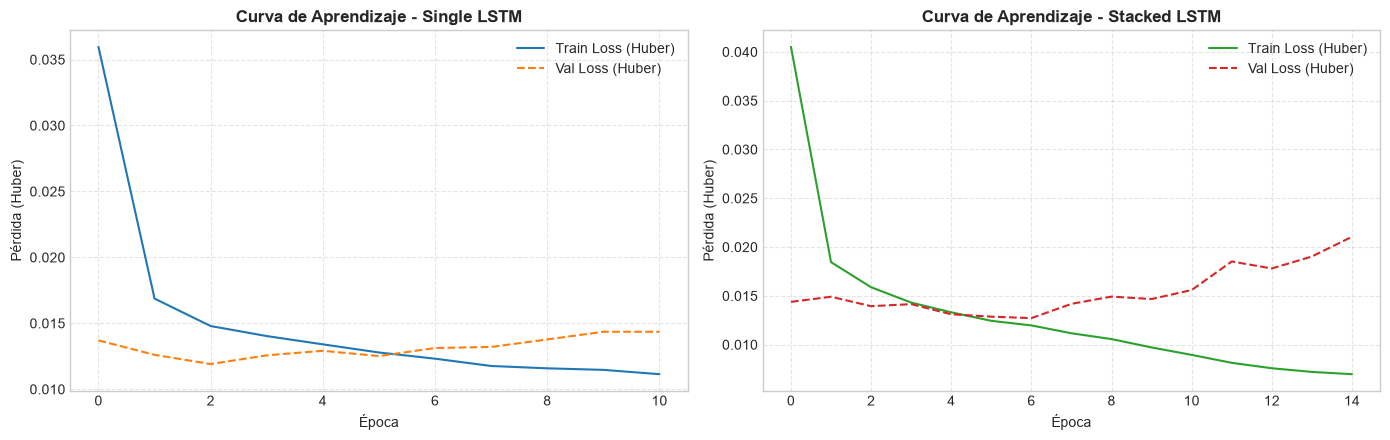

In [14]:
# Comparación de Curvas de Aprendizaje (Pérdida de Entrenamiento vs Validación)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.plot(history_single.history['loss'], label='Train Loss (Huber)', color='#1f77b4')
ax1.plot(history_single.history['val_loss'], label='Val Loss (Huber)', color='#ff7f0e', linestyle='--')
ax1.set_title('Curva de Aprendizaje - Single LSTM', fontweight='bold')
ax1.set_xlabel('Época')
ax1.set_ylabel('Pérdida (Huber)')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.plot(history_stacked.history['loss'], label='Train Loss (Huber)', color='#2ca02c')
ax2.plot(history_stacked.history['val_loss'], label='Val Loss (Huber)', color='#d62728', linestyle='--')
ax2.set_title('Curva de Aprendizaje - Stacked LSTM', fontweight='bold')
ax2.set_xlabel('Época')
ax2.set_ylabel('Pérdida (Huber)')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## 9. Evaluación de Rendimiento sobre el Conjunto de Prueba
Se obtienen las predicciones sobre el conjunto de test, se invierte el escalado a $\text{MWh}$ y se evalúan las métricas formales:
* **RMSE (Root Mean Squared Error):** Penalización cuadrática para evaluar precisión en crestas de demanda.
* **MAE (Mean Absolute Error):** Error lineal medio en magnitud de potencia.
* **MAPE (Mean Absolute Percentage Error):** Error porcentual relativo sobre valores reales $> 1\text{ MWh}$.
* **$R^2$ Score:** Coeficiente de determinación sobre la serie real.


In [15]:
# Predicciones normalizadas en test
y_pred_single_scaled = model_single_lstm.predict(X_test_seq)
y_pred_stacked_scaled = model_stacked_lstm.predict(X_test_seq)

# Inversión de escala al rango original de MWh
def inverse_multistep(y_scaled, scaler):
    original_shape = y_scaled.shape
    flattened = y_scaled.reshape(-1, 1)
    inv_flattened = scaler.inverse_transform(flattened)
    return inv_flattened.reshape(original_shape)

y_test_real = inverse_multistep(y_test_seq, scaler_y)
y_pred_single_real = inverse_multistep(y_pred_single_scaled, scaler_y)
y_pred_stacked_real = inverse_multistep(y_pred_stacked_scaled, scaler_y)

# Función de métricas globales extraídas directamente de los arreglos numéricos
def calcular_metricas(y_true, y_pred):
    y_t_flat = y_true.flatten()
    y_p_flat = y_pred.flatten()
    
    rmse = np.sqrt(mean_squared_error(y_t_flat, y_p_flat))
    mae = mean_absolute_error(y_t_flat, y_p_flat)
    
    # Filtro de umbral menor para evitar indeterminaciones en MAPE
    mask = y_t_flat > 1.0
    mape = np.mean(np.abs((y_t_flat[mask] - y_p_flat[mask]) / y_t_flat[mask])) * 100
    r2 = r2_score(y_t_flat, y_p_flat)
    
    return {'RMSE (MWh)': rmse, 'MAE (MWh)': mae, 'MAPE (%)': mape, 'R2': r2}

metricas_single = calcular_metricas(y_test_real, y_pred_single_real)
metricas_stacked = calcular_metricas(y_test_real, y_pred_stacked_real)

df_metricas = pd.DataFrame([metricas_single, metricas_stacked], index=['Single LSTM', 'Stacked LSTM'])
df_metricas.round(3)


50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


,RMSE (MWh),MAE (MWh),MAPE (%),R2
Single LSTM,143.777,114.258,22.890,0.540
Stacked LSTM,165.062,128.665,25.664,0.394


### Comparación con un modelo de referencia y sesgo de los residuos
Para saber si las LSTM aportan algo, se compara con un pronóstico ingenuo: repetir la generación de las mismas 24 horas del día anterior (últimas 24 horas de la ventana de entrada). También se calcula la media de los residuos (Real − Predicho), que indica si hay sesgo.


In [16]:
# Referencia ingenua: se repite el último día observado (mismas horas, 24 h antes)
y_naive = inverse_multistep(X_test_seq[:, -24:, 0], scaler_y)  # la columna 0 de X es Energía_Molino
metricas_naive = calcular_metricas(y_test_real, y_naive)

df_comp = pd.DataFrame([metricas_naive, metricas_single, metricas_stacked],
                       index=['Naive (día anterior)', 'Single LSTM', 'Stacked LSTM'])
df_comp['Sesgo medio (MWh)'] = [np.mean(y_test_real - y_naive),
                                np.mean(y_test_real - y_pred_single_real),
                                np.mean(y_test_real - y_pred_stacked_real)]
print(f"Media de Energía_Molino: train {train_df[TARGET].mean():.1f} | val {val_df[TARGET].mean():.1f} | test {test_df[TARGET].mean():.1f} MWh")
df_comp.round(3)


Media de Energía_Molino: train 473.0 | val 203.2 | test 575.1 MWh


,RMSE (MWh),MAE (MWh),MAPE (%),R2,Sesgo medio (MWh)
Naive (día anterior),169.306,120.912,25.535,0.362,8.402
Single LSTM,143.777,114.258,22.890,0.540,28.590
Stacked LSTM,165.062,128.665,25.664,0.394,46.864


## 10. Visualización de Pronósticos y Análisis de Residuos
Comparación gráfica del perfil horario proyectado a 24 horas vista frente al despacho real en ventanas del conjunto de prueba.


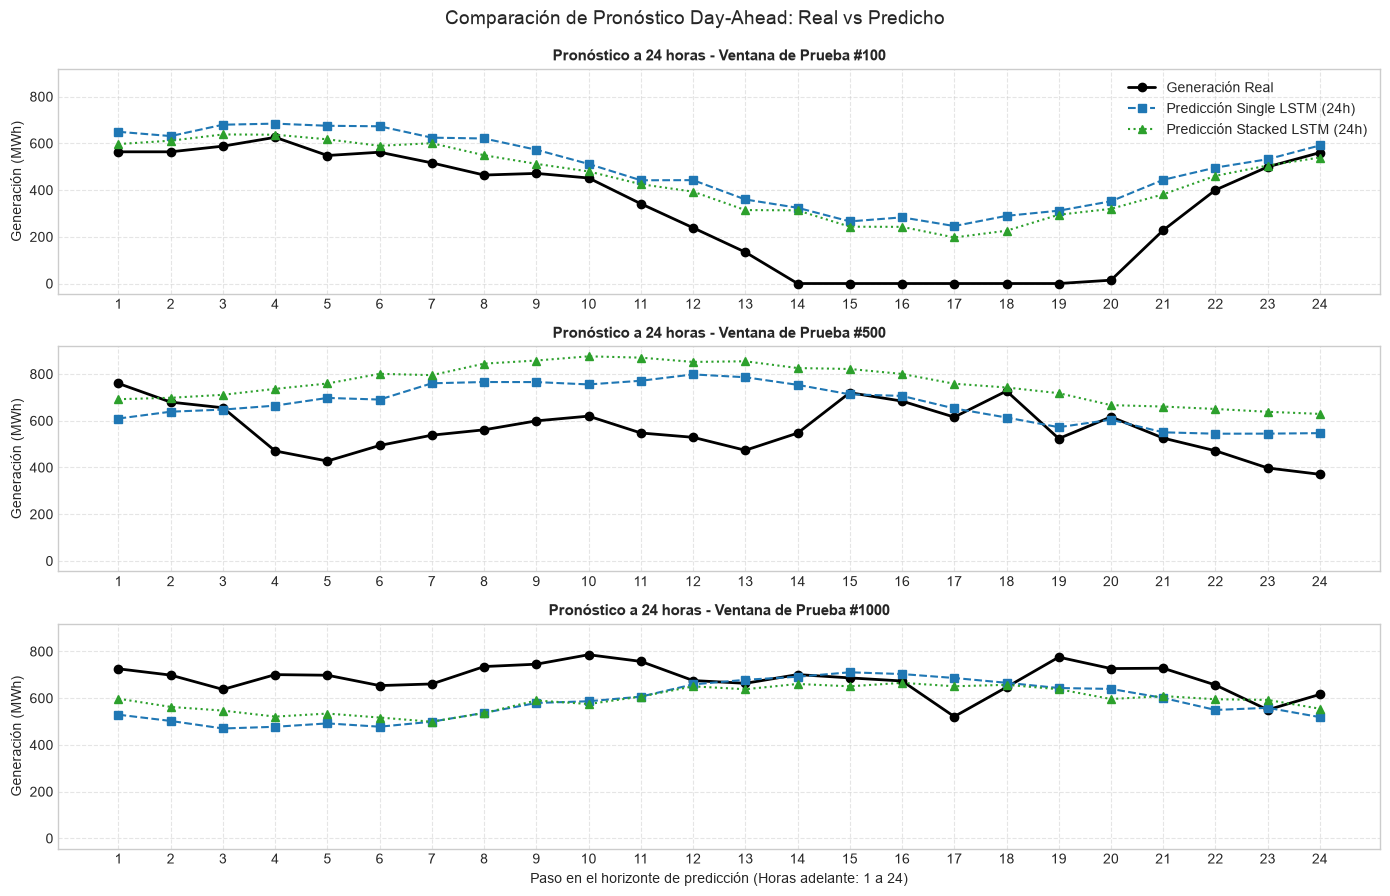

In [17]:
# Selección de 3 ventanas representativas de prueba
indices_ejemplos = [100, 500, 1000]

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharey=True)

for i, idx in enumerate(indices_ejemplos):
    ax = axes[i]
    horas_horizonte = np.arange(1, HORIZON + 1)
    
    ax.plot(horas_horizonte, y_test_real[idx], label='Generación Real', color='black', linewidth=2, marker='o')
    ax.plot(horas_horizonte, y_pred_single_real[idx], label='Predicción Single LSTM (24h)', color='#1f77b4', linestyle='--', marker='s')
    ax.plot(horas_horizonte, y_pred_stacked_real[idx], label='Predicción Stacked LSTM (24h)', color='#2ca02c', linestyle=':', marker='^')
    
    ax.set_title(f'Pronóstico a 24 horas - Ventana de Prueba #{idx}', fontweight='bold', fontsize=11)
    ax.set_ylabel('Generación (MWh)')
    ax.set_xticks(horas_horizonte)
    ax.grid(True, linestyle='--', alpha=0.5)
    if i == 0:
        ax.legend(loc='upper right')

axes[-1].set_xlabel('Paso en el horizonte de predicción (Horas adelante: 1 a 24)')
plt.suptitle('Comparación de Pronóstico Day-Ahead: Real vs Predicho', fontsize=14, y=0.99)
plt.tight_layout()
plt.show()


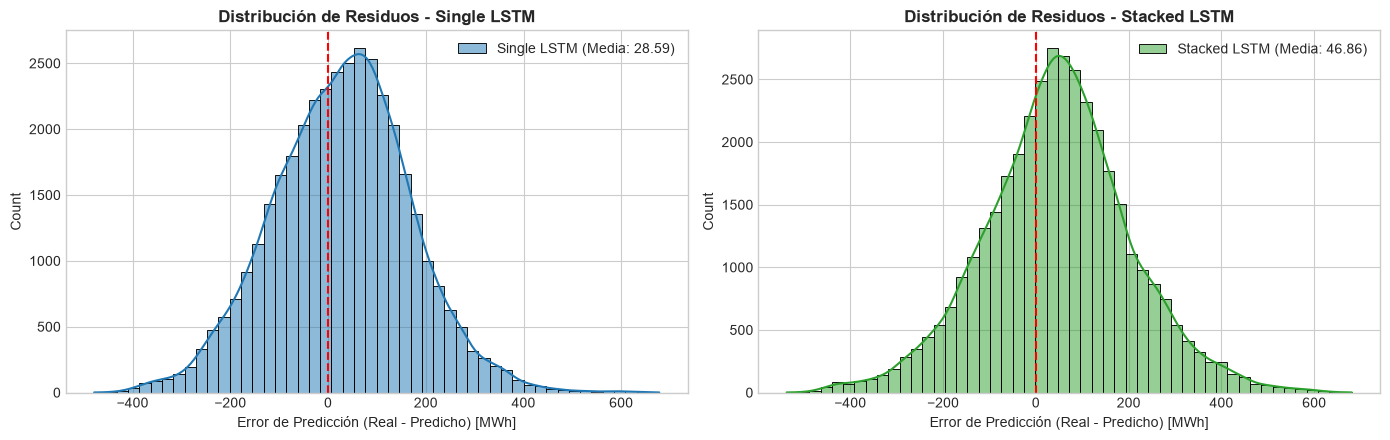

In [18]:
# Análisis de Residuos (Distribución del error Real - Predicho)
residuos_single = (y_test_real - y_pred_single_real).flatten()
residuos_stacked = (y_test_real - y_pred_stacked_real).flatten()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(residuos_single, bins=50, kde=True, ax=ax1, color='#1f77b4', label=f'Single LSTM (Media: {np.mean(residuos_single):.2f})')
sns.histplot(residuos_stacked, bins=50, kde=True, ax=ax2, color='#2ca02c', label=f'Stacked LSTM (Media: {np.mean(residuos_stacked):.2f})')

ax1.axvline(0, color='red', linestyle='--')
ax1.set_title('Distribución de Residuos - Single LSTM', fontweight='bold')
ax1.set_xlabel('Error de Predicción (Real - Predicho) [MWh]')
ax1.legend()

ax2.axvline(0, color='red', linestyle='--')
ax2.set_title('Distribución de Residuos - Stacked LSTM', fontweight='bold')
ax2.set_xlabel('Error de Predicción (Real - Predicho) [MWh]')
ax2.legend()

plt.tight_layout()
plt.show()


## 11. Conclusiones

### 1. Single LSTM frente a Stacked LSTM
* En el conjunto de prueba el Single LSTM obtuvo mejores métricas que el Stacked: RMSE 143.78 vs 165.06 MWh, MAE 114.26 vs 128.67 MWh, MAPE 22.89% vs 25.66% y R² 0.540 vs 0.394.
* El Stacked muestra sobreajuste claro: su pérdida de entrenamiento baja hasta ~0.007 mientras la de validación sube desde la época 7 hasta ~0.021. El Single paró en la época 11 y restauró los pesos de la época 3; el Stacked paró en la época 15 y restauró los de la época 7.
* Los resultados varían entre ejecuciones. En una corrida anterior del mismo código el Single dio RMSE 153.02 y el Stacked 157.46, con una diferencia mucho menor. Con una sola semilla por corrida no se puede asegurar cuánto de la ventaja del Single es de la arquitectura y cuánto del azar del entrenamiento; habría que repetir con varias semillas.

### 2. Frente a un modelo de referencia
* El pronóstico ingenuo que repite el día anterior da RMSE 169.31, MAE 120.91 y R² 0.362 sobre las mismas ventanas (celda de comparación de la sección 9).
* El Single LSTM lo supera en las cuatro métricas (RMSE 15% menor, MAE 5.5% menor), aunque la mejora en MAE es pequeña.
* El Stacked apenas mejora el RMSE (165.06) y tiene un MAE peor que el ingenuo (128.67 vs 120.91), por lo que en esta corrida no justifica su mayor complejidad.

### 3. Ventana de 72 horas y variables de entrada
* La autocorrelación de Molino es alta a 1 h (0.967) y sigue en 0.57 a 72 h. Esto es compatible con usar 72 horas de contexto, pero no se probaron otras ventanas, por lo que no sabemos si es la mejor.
* La correlación cruzada Mazar–Molino es máxima en lag 0 y casi simétrica; no se detectó el retardo aguas arriba que planteaba la consigna.
* No se hizo ninguna prueba de ablación, así que no podemos decir cuánto aportan Mazar, las unidades ni las variables de calendario al resultado.

### 4. Errores y sesgo
* El MAPE de 22.89% (Single) y el MAE de 114.26 MWh son altos frente a una media de 447.89 MWh. El MAPE se calcula solo con valores reales mayores a 1 MWh, por lo que excluye las horas de generación cero.
* Los residuos no están centrados en cero: la media (Real − Predicho) es +28.59 MWh en el Single y +46.86 MWh en el Stacked, es decir, ambos subestiman en promedio. Esto es coherente con que la media de Molino es 473 MWh en entrenamiento, 203 en validación y 575 en prueba: los modelos se detuvieron con una validación de baja generación y se evaluaron en un periodo de generación alta. El pronóstico ingenuo tiene un sesgo mucho menor (+8.40 MWh), lo que apunta a que parte del error de las LSTM viene de ese cambio de régimen.
* En la ventana de prueba #100 ambos modelos no anticipan la caída a 0 MWh entre las horas 14 y 20: predicen entre unos 200 y 350 MWh. Los paros bruscos son el caso que peor se predice.

### 5. Validez de la evaluación
* La partición es cronológica y los escaladores se ajustaron solo con entrenamiento, y las comprobaciones de la sección 6 lo confirman, por lo que no hay fuga de información entre conjuntos.
* Aun así, el resultado depende de un único periodo de prueba (enero–abril de 2025), de una sola corrida y de un dataset de 15 meses que contiene un solo periodo de baja generación. Las métricas deben leerse como una estimación para ese tramo, no como el desempeño general del modelo.

### 6. Limitaciones y trabajo futuro
* El modelo no recibe caudales afluentes ni las decisiones de despacho, por lo que es esperable que falle ante cambios operativos bruscos.
* No se evaluaron horizontes mayores a 24 horas; antes de usar un esquema recursivo habría que medir cómo crece el error.
* Mejoras posibles: repetir con varias semillas, probar otras ventanas, añadir caudal o precipitación y validar con más de un periodo (validación cruzada temporal).